<a href="https://colab.research.google.com/github/yolohe1210/cse450/blob/main/module5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Note: After you run this cell, the training and test data will be available in
# the file browser. (Click the folder icon on the left to view it)
#
# If you don't see the data after the cell completes, click the refresh button
# in the file browser (folder icon with circular arrow)

# First, let's download and unzip the data
!echo "Downloading files..."
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training1.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training2.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout_answers.csv

!echo "Unzipping files..."
!unzip -q /content/training1.zip
!unzip -q /content/training2.zip
!unzip -q /content/holdout.zip
!unzip -q /content/mini_holdout.zip

# Combine the two traning directories
!echo "Merging training data..."
!mkdir /content/training
!mv /content/training1/* /content/training
!mv /content/training2/* /content/training

# Cleanup
!echo "Cleaning up..."
!rmdir /content/training1
!rmdir /content/training2
!rm training1.zip
!rm training2.zip
!rm holdout.zip
!rm mini_holdout.zip

!echo "Data ready."

Unzipping files...
Merging training data...
Cleaning up...
Data ready.


In [17]:
# Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [8]:
# We're using keras' ImageDataGenerator class to load our image data.
# See (https://keras.io/api/preprocessing/image/#imagedatagenerator-class) for details
#
# A couple of things to note:
# 1. We're specifying a number for the seed, so we'll always get the same shuffle and split of our images.
# 2. Class names are inferred automatically from the image subdirectory names.
# 3. We're splitting the training data into 80% training, 20% validation.


training_dir = '/content/training/'
image_size = (100, 100)

# Split up the training data images into training and validations sets
# We'll use and ImageDataGenerator to do the splits
# ImageDataGenerator can also be used to do preprocessing and agumentation on the files as can be seen with rescale

train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )

train_generator = train_datagen.flow_from_directory(
        training_dir,
        target_size = image_size,
        subset="training",
        batch_size=32,
        class_mode='sparse',
        seed=42,shuffle=True)
validation_generator = validation_datagen.flow_from_directory(
        training_dir,
        target_size=image_size,
        batch_size=32,
        class_mode='sparse',
        subset="validation",
        seed=42)



Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [9]:
#these might come in handy
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

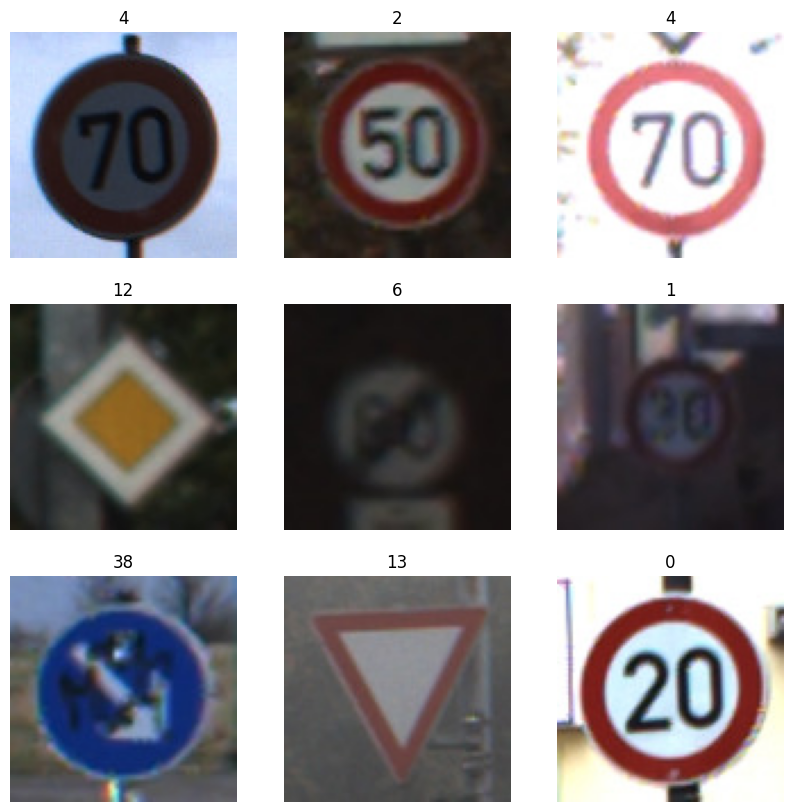

In [10]:
# View 9 images and their class labels
plt.figure(figsize=(10, 10))
images, labels = next(train_generator)  # Assuming train_generator is a generator
batch_size = images.shape[0]

for i in range(min(9, batch_size)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((images[i] * 255).astype("uint8"))
    plt.title(int(labels[i]))
    plt.axis("off")

plt.show()

In [12]:
# Build a model...
from tensorflow.keras import layers
model = keras.Sequential([
    layers.Input(shape=(100, 100, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(43, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,737,323 (6.63 MB)

 Trainable params: 1,737,323 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
)

Epoch 1/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 51s 41ms/step - accuracy: 0.7708 - loss: 0.7991 - val_accuracy: 0.8549 - val_loss: 0.5679
Epoch 2/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.9672 - loss: 0.1168 - val_accuracy: 0.8986 - val_loss: 0.4122
Epoch 3/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.9802 - loss: 0.0667 - val_accuracy: 0.9333 - val_loss: 0.3009
Epoch 4/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.9840 - loss: 0.0552 - val_accuracy: 0.9075 - val_loss: 0.4501
Epoch 5/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.9891 - loss: 0.0375 - val_accuracy: 0.9300 - val_loss: 0.3482
Epoch 6/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - accuracy: 0.9874 - loss: 0.0445 - val_accuracy: 0.9459 - val_loss: 0.2552
Epoch 7/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.9911 - loss: 0.0310 - val_accuracy: 0.9283 - val_loss: 0.3529
Epoch 8/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 34s 34ms/step - accuracy: 0.9903 - loss: 0.0316 - 

In [14]:
model.save("roadsigns_model.keras")

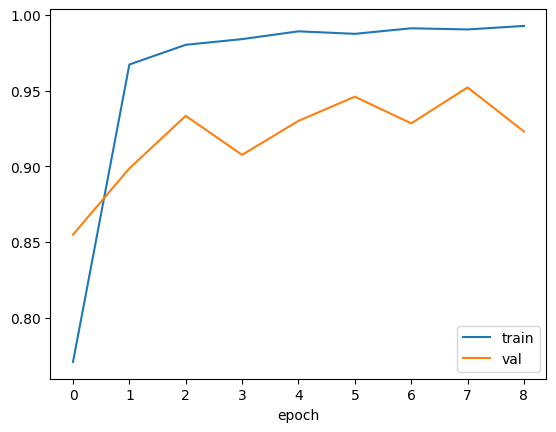

In [15]:
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.xlabel("epoch"); plt.legend(); plt.show()

In [18]:
eval_datagen = ImageDataGenerator(rescale=1./255, validation_split=.2)
eval_generator = eval_datagen.flow_from_directory(
    training_dir, target_size=image_size, batch_size=32,
    class_mode='sparse', subset="validation", shuffle=False)

probs = model.predict(eval_generator)
preds = np.argmax(probs, axis=1)
y_true = eval_generator.classes

print(classification_report(y_true, preds))

Found 7841 images belonging to 43 classes.
246/246 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.88      0.97      0.92       444
           2       0.97      0.92      0.95       450
           3       0.91      0.96      0.93       282
           4       0.99      0.94      0.97       396
           5       0.92      0.93      0.92       372
           6       0.98      1.00      0.99        84
           7       1.00      0.91      0.95       288
           8       0.88      0.97      0.93       282
           9       0.99      0.98      0.98       294
          10       0.97      1.00      0.99       402
          11       0.96      0.95      0.95       264
          12       1.00      1.00      1.00       420
          13       0.99      0.99      0.99       432
          14       1.00      0.97      0.98       156
          15       0.98      0.95      0.97       

In [34]:
cm = confusion_matrix(y_true, preds)

def top_confusions(cls, k=3):
    row = cm[cls].copy()
    row[cls] = 0
    idx = np.argsort(row)[::-1][:k]
    return [(int(i), int(row[i])) for i in idx if row[i] > 0]

for c in [32, 20, 29, 30]:
    print(c, "misclassified as (class, count):", top_confusions(c))

32 misclassified as (class, count): [(3, 18), (5, 5), (34, 4)]
20 misclassified as (class, count): [(28, 15), (25, 4), (11, 4)]
29 misclassified as (class, count): [(25, 15), (21, 7), (31, 3)]
30 misclassified as (class, count): [(25, 7), (26, 5), (23, 2)]


In [20]:
test_dir = '/content/'
test_datagen = ImageDataGenerator(rescale=1./255)

mini_generator = test_datagen.flow_from_directory(
    test_dir, classes=['mini_holdout'], target_size=image_size,
    class_mode='sparse', shuffle=False)

mini_probs = model.predict(mini_generator)
mini_preds = [np.argmax(p) for p in mini_probs]

Found 201 images belonging to 1 classes.
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 375ms/step


In [35]:
answers = pd.read_csv("/content/mini_holdout_answers.csv")

pred_df = pd.DataFrame({
    "Filename": [f.split("/")[-1] for f in mini_generator.filenames],
    "Pred": mini_preds
})

merged = answers.merge(pred_df, on="Filename")
print("Number of images:", len(merged))
print("Mini holdout accuracy:", accuracy_score(merged["ClassId"], merged["Pred"]))
print(classification_report(merged["ClassId"], merged["Pred"], zero_division=0))

Number of images: 201
Mini holdout accuracy: 0.9303482587064676
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         8
           3       1.00      0.90      0.95        10
           4       1.00      1.00      1.00         9
           5       0.62      1.00      0.77         5
           6       1.00      1.00      1.00         3
           7       1.00      0.75      0.86         8
           8       0.71      0.83      0.77         6
           9       1.00      1.00      1.00        10
          10       1.00      1.00      1.00        12
          11       0.89      1.00      0.94         8
          12       1.00      1.00      1.00         7
          13       1.00      1.00      1.00        10
          14       1.00      1.00      1.00         4
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         5
          17     

In [22]:
merged["Correct"] = merged["ClassId"] == merged["Pred"]
wrong_rows = merged[~merged["Correct"]].sort_values("ClassId")
print(wrong_rows)

      Filename  ClassId  Pred  Correct
176  00176.jpg        3     5    False
13   00013.jpg        7     8    False
83   00083.jpg        7     8    False
49   00049.jpg        8     5    False
198  00198.jpg       18    11    False
48   00048.jpg       18    31    False
33   00033.jpg       23    19    False
50   00050.jpg       25    18    False
163  00163.jpg       25    27    False
145  00145.jpg       25     5    False
69   00069.jpg       28    25    False
117  00117.jpg       29    25    False
127  00127.jpg       30    26    False
197  00197.jpg       38    32    False


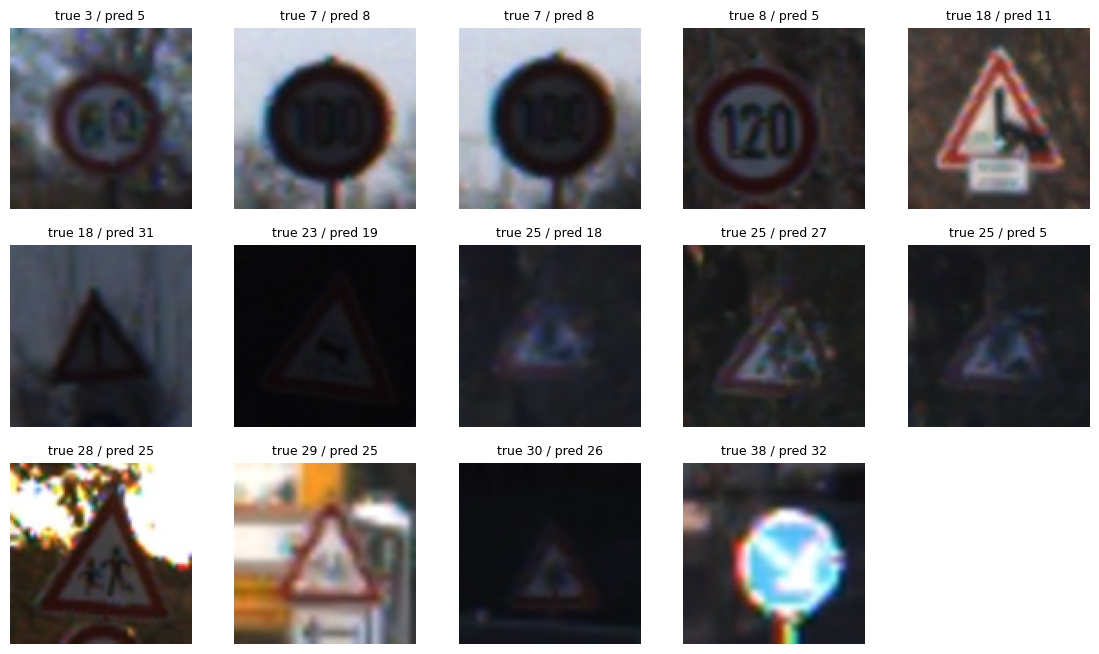

In [23]:
plt.figure(figsize=(14, 8))
for i, (_, r) in enumerate(wrong_rows.iterrows()):
    img = plt.imread(f"/content/mini_holdout/{r['Filename']}")
    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(f"true {r['ClassId']} / pred {r['Pred']}", fontsize=9)
    plt.axis("off")
plt.show()

In [24]:
holdout_generator = test_datagen.flow_from_directory(
    test_dir, classes=['holdout'], target_size=image_size,
    class_mode='sparse', shuffle=False)

holdout_probs = model.predict(holdout_generator)
holdout_preds = [np.argmax(p) for p in holdout_probs]
print(len(holdout_preds))

Found 12630 images belonging to 1 classes.
395/395 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step
12630


In [36]:
submission = pd.DataFrame({"predictions": [int(p) for p in holdout_preds]})
submission.to_csv("predictions.csv", index=False)

print(submission.shape)
print(submission.head())

(12630, 1)
   predictions
0           16
1            1
2           38
3           33
4           11


In [33]:
from google.colab import files
files.download("predictions.csv")
files.download("roadsigns_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>